In [1]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import torch.optim as optim

In [2]:
train_dir=r'2_class'
test_dir=r'classification'

In [3]:
# 将图片转为张量数据
from torchvision import transforms

In [4]:
# 可以设置一个专门的转换函数，把转换图像的两个步骤整合在一起
# 1.将图像转为浮点的张量（rgb》0-255）转为浮点数（0-1）
# 2.把图片数据标准化处理，大致是-1到1，（数值-均值）/标准差

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5],std=[0.5,0.5,0.5])
])

In [5]:
# torchvision加载图片
train_ds = torchvision.datasets.ImageFolder(
    train_dir,
    transform=transform
)

test_ds = torchvision.datasets.ImageFolder(
    test_dir,
    transform=transform
)

In [6]:
train_ds.classes

['airplane', 'lake']

In [7]:
len(train_ds),len(test_ds)

(1400, 480)

In [8]:
BATCHSIZE=16

In [9]:
train_dl=torch.utils.data.DataLoader(
    train_ds,
    batch_size=BATCHSIZE,
    # 打乱图片顺序
    shuffle = True
)

test_dl=torch.utils.data.DataLoader(
    test_ds,
    batch_size=BATCHSIZE
)

In [10]:
imgs,label = next(iter(train_dl))

In [11]:
imgs.shape

torch.Size([16, 3, 256, 256])

In [12]:
imgs[0].shape

torch.Size([3, 256, 256])

In [13]:
# 改变图片默认的存储顺序
im = imgs[0].permute(1,2,0)
im.shape

torch.Size([256, 256, 3])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.6627451].


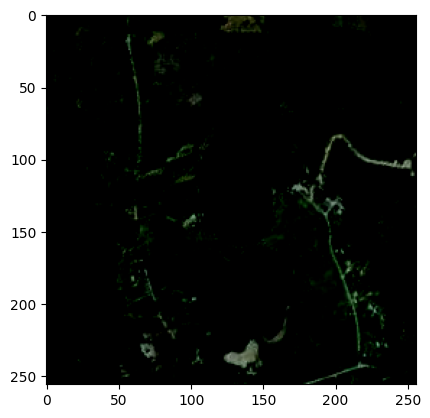

In [14]:
import matplotlib.pyplot as plt
plt.imshow(im)

In [15]:
class NetModel1(nn.Module):
    def __init__(self):
        super(NetModel1,self).__init__()
        # 输入通道是3，三层颜色，3*3的卷积核
        self.conv1=nn.Conv2d(3,16,3)
        self.conv2=nn.Conv2d(16,32,3)
        self.conv3=nn.Conv2d(32,64,3)

        # 2层全连接
        self.fc1 = nn.Linear(64*30*30,1024)
        self.fc2 = nn.Linear(1024,2)

    # 定义前向传播函数
    def forward(self,x):
        
        # 将输入到卷积层1
        x=self.conv1(x)
        # 接着输入到激活函数
        x=F.relu(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2)
        # 将输入到卷积层2
        x=self.conv2(x)
        # 接着输入到激活函数
        x=F.relu(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2)
        # 将输入到卷积层3
        x=self.conv3(x)
        # 接着输入到激活函数
        x=F.relu(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2)


        # 全连接层
        x=x.view(-1,64*30*30)
        # 将输入给到第一层线性层(全连接层)
        x = self.fc1(x)
        # 使用relu激活函数
        x = F.relu(x)
        # 将输入给到第二层线性层
        x = self.fc2(x)
        # 返回结果
        return x
        

In [16]:
# 进行填充
class NetModel2(nn.Module):
    def __init__(self):
        super(NetModel2,self).__init__()
        # 输入通道是3，三层颜色，3*3的卷积核
        self.conv1=nn.Conv2d(3,16,3)
        self.conv2=nn.Conv2d(16,32,3)
        self.conv3=nn.Conv2d(32,64,3)

        # 2层全连接
        self.fc1 = nn.Linear(64*31*31,1024)
        self.fc2 = nn.Linear(1024,2)

    # 定义前向传播函数
    def forward(self,x):
        
        # 将输入到卷积层1
        x=self.conv1(x)
        # 接着输入到激活函数
        x=F.relu(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2)
        # 将输入到卷积层2
        x=self.conv2(x)
        # 接着输入到激活函数
        x=F.relu(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2,padding=1)
        # 将输入到卷积层3
        x=self.conv3(x)
        # 接着输入到激活函数
        x=F.relu(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2,padding=1)


        # 全连接层
        x=x.view(-1,64*31*31)
        # 将输入给到第一层线性层(全连接层)
        x = self.fc1(x)
        # 使用relu激活函数
        x = F.relu(x)
        # 将输入给到第二层线性层
        x = self.fc2(x)
        # 返回结果
        return x
        

In [17]:
# 进行dropout（减支）操作
class NetModel3(nn.Module):
    def __init__(self):
        super(NetModel3,self).__init__()
        # 输入通道是3，三层颜色，3*3的卷积核
        self.conv1=nn.Conv2d(3,16,3)
        self.conv2=nn.Conv2d(16,32,3)
        self.conv3=nn.Conv2d(32,64,3)

        # 2层全连接
        self.fc1 = nn.Linear(64*31*31,1024)
        self.fc2 = nn.Linear(1024,2)

    # 定义前向传播函数
    def forward(self,x):
        
        # 将输入到卷积层1
        x=self.conv1(x)
        # 接着输入到激活函数
        x=F.relu(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2)
        # 将输入到卷积层2
        x=self.conv2(x)
        # 接着输入到激活函数
        x=F.relu(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2,padding=1)
        # 将输入到卷积层3
        x=self.conv3(x)
        # 接着输入到激活函数
        x=F.relu(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2,padding=1)


        # 全连接层
        x=x.view(-1,64*31*31)

        # 进行dropout操作防止过拟合
        x = F.dropout(x)
        # 不设置参数，默认0.5（一半的节点不工作）
        # 将输入给到第一层线性层(全连接层)
        x = self.fc1(x)
        # 使用relu激活函数
        x = F.relu(x)

        # 进行dropout操作防止过拟合
        x = F.dropout(x)
        # 将输入给到第二层线性层
        x = self.fc2(x)
        # 返回结果
        return x
        

In [18]:
# 批量归一化处理
# 让网络不再那么依赖初始值
class NetModel4(nn.Module):
    def __init__(self):
        super(NetModel4,self).__init__()
        # 输入通道是3，三层颜色，3*3的卷积核
        self.conv1=nn.Conv2d(3,16,3)
        # 批量归一化
        self.bn1 = nn.BatchNorm2d(16)
        self.conv2=nn.Conv2d(16,32,3)
        # 批量归一化
        self.bn2 = nn.BatchNorm2d(32)
        self.conv3=nn.Conv2d(32,64,3)
        # 批量归一化
        self.bn3 = nn.BatchNorm2d(64)

        # 2层全连接
        self.fc1 = nn.Linear(64*31*31,1024)
        self.fc2 = nn.Linear(1024,2)

    # 定义前向传播函数
    def forward(self,x):
        
        # 将输入到卷积层1
        x=self.conv1(x)
        # 接着输入到激活函数
        x=F.relu(x)
        # 归一化
        x=self.bn1(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2)
        # 将输入到卷积层2
        x=self.conv2(x)
        # 接着输入到激活函数
        x=F.relu(x)
        x=self.bn2(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2,padding=1)
        # 将输入到卷积层3
        x=self.conv3(x)
        # 接着输入到激活函数
        x=F.relu(x)
        x=self.bn3(x)
        # 使用最大池化层，设置步长为2
        x=F.max_pool2d(x,2,padding=1)


        # 全连接层
        x=x.view(-1,64*31*31)
        # 将输入给到第一层线性层(全连接层)
        x = self.fc1(x)
        # 使用relu激活函数
        x = F.relu(x)
        # 将输入给到第二层线性层
        x = self.fc2(x)
        # 返回结果
        return x
        

In [19]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [20]:
model1 = NetModel1().to(device)
model2 = NetModel2().to(device)
model3 = NetModel3().to(device)
model4 = NetModel4().to(device)

In [21]:
# 定义损失函数
loss_fn = torch.nn.CrossEntropyLoss()
# 定义优化器
optimizer1 = torch.optim.Adam(model1.parameters(),lr=0.001)
optimizer2 = torch.optim.Adam(model2.parameters(),lr=0.001)
optimizer3 = torch.optim.Adam(model3.parameters(),lr=0.001)
optimizer4 = torch.optim.Adam(model4.parameters(),lr=0.001)

In [22]:
# 定义训练函数，从训练加载器里提取训练数据，进行训练
def train(dataLoader,model,loss_fn,optimizer):
    # 获取整个训练数据集大小
    size = len(dataLoader.dataset)
    train_loss,correct=0,0      
    # 循环遍历整个数据集
    for X,Y in dataLoader:
        X,Y=X.to(device),Y.to(device)
        # 进行初步预测
        pred=model(X)
        # 查看误差
        loss = loss_fn(pred,Y)

        # 梯度归零
        optimizer.zero_grad()
        # 反向传播
        loss.backward()
        # 使用优化器更新参数
        optimizer.step()

        # 计算当前准确率
        # 计算准确率不需要更新梯度
        with torch.no_grad():
            # 在10个数据里挑最大值
            correct += (pred.argmax(1)==Y).type(torch.float).sum().item()
            # 获取当前训练的损失值
            train_loss +=loss.item()
    # 计算平均损失和正确率
    train_loss = train_loss / size
    correct = correct/size
    return train_loss,correct
        

In [23]:
# 定义一个测试函数
def test(dataLoader,model):
    # 获取测试集大小
    size = len(dataLoader.dataset)
    train_loss, correct = 0, 0
     # 计算准确率不需要更新梯度
    with torch.no_grad():
        for X,Y in dataLoader:
            X,Y=X.to(device),Y.to(device)
            # 进行初步预测
            pred=model(X)
            # 查看误差
            loss = loss_fn(pred,Y)
            # 在10个数据里挑最大值
            correct += (pred.argmax(1)==Y).type(torch.float).sum().item()
            # 获取当前训练的损失值
            train_loss +=loss.item()
    # 计算平均损失和正确率
    train_loss = train_loss / size
    correct = correct/size
    return train_loss,correct

In [22]:
# 训练多轮
epochs = 10
train_acc=[]
test_acc=[]


# 保存最佳的准确率
best_acc = 0.0
best_acc_index=0
for epoch in range(epochs):
    epoch_loss,epoch_acc = train(train_dl,model1,loss_fn,optimizer1)
    epoch_test_loss,epoch_test_acc = test(test_dl,model1)
    train_acc.append(epoch_acc)
    test_acc.append(epoch_test_acc)
    print('epoch:{},train_loss:{},train_acc{}'.format(epoch,epoch_loss,epoch_acc))
    print('epoch:{},test_loss:{},test_acc{}'.format(epoch,epoch_test_loss,epoch_test_acc))
    print('---------------------------------')
    if epoch_test_acc > best_acc:
        print('保存最佳准确率模型')
        best_acc = epoch_test_acc
        best_acc_index = best_acc_index+1
        # 保存参数
        torch.save(model1.state_dict(),'best_model_weights'+str(best_acc_index)+'.pth')

epoch:0,train_loss:0.018361283312052754,train_acc0.8964285714285715
epoch:0,test_loss:0.02744559211047317,test_acc0.8166666666666667
---------------------------------
保存最佳准确率模型
epoch:1,train_loss:0.007442232101124578,train_acc0.9592857142857143
epoch:1,test_loss:0.0020388313557001916,test_acc0.9895833333333334
---------------------------------
保存最佳准确率模型
epoch:2,train_loss:0.003640636365827439,train_acc0.9814285714285714
epoch:2,test_loss:0.0012422423645148228,test_acc0.9916666666666667
---------------------------------
保存最佳准确率模型
epoch:3,train_loss:0.00167397105236887,train_acc0.9914285714285714
epoch:3,test_loss:0.0017804924066012972,test_acc0.99375
---------------------------------
保存最佳准确率模型
epoch:4,train_loss:0.002352317358672735,train_acc0.9857142857142858
epoch:4,test_loss:0.0012665622702722128,test_acc0.9979166666666667
---------------------------------
保存最佳准确率模型
epoch:5,train_loss:0.0011665638238394292,train_acc0.9942857142857143
epoch:5,test_loss:0.0015725622818095531,test_acc0.

In [23]:
# 训练多轮
epochs = 10
train_acc=[]
test_acc=[]


# 保存最佳的准确率
best_acc = 0.0
best_acc_index=0
for epoch in range(epochs):
    epoch_loss,epoch_acc = train(train_dl,model2,loss_fn,optimizer2)
    epoch_test_loss,epoch_test_acc = test(test_dl,model2)
    train_acc.append(epoch_acc)
    test_acc.append(epoch_test_acc)
    print('epoch:{},train_loss:{},train_acc{}'.format(epoch,epoch_loss,epoch_acc))
    print('epoch:{},test_loss:{},test_acc{}'.format(epoch,epoch_test_loss,epoch_test_acc))
    print('---------------------------------')
    if epoch_test_acc > best_acc:
        print('保存最佳准确率模型')
        best_acc = epoch_test_acc
        best_acc_index = best_acc_index+1
        # 保存参数.优化器，轮数.方便后续继续学习
        torch.save({
            'epoch':epoch,
            'model_state_dict':model2.state_dict(),
            'optimizer_state_dict':optimizer2.state_dict()
        },'best_checkpoint.pt')

epoch:0,train_loss:0.020948189988931908,train_acc0.8864285714285715
epoch:0,test_loss:0.005647395440610126,test_acc0.9729166666666667
---------------------------------
保存最佳准确率模型
epoch:1,train_loss:0.005815239023483757,train_acc0.9664285714285714
epoch:1,test_loss:0.0041039438143949765,test_acc0.975
---------------------------------
保存最佳准确率模型
epoch:2,train_loss:0.004039293174199494,train_acc0.9821428571428571
epoch:2,test_loss:0.0031619797603677094,test_acc0.9854166666666667
---------------------------------
保存最佳准确率模型
epoch:3,train_loss:0.0030774588828041617,train_acc0.9807142857142858
epoch:3,test_loss:0.0024503678682625224,test_acc0.9895833333333334
---------------------------------
保存最佳准确率模型
epoch:4,train_loss:0.0018950675824635254,train_acc0.9907142857142858
epoch:4,test_loss:0.0012496564277171274,test_acc0.9895833333333334
---------------------------------
epoch:5,train_loss:0.0027975139965461236,train_acc0.9878571428571429
epoch:5,test_loss:0.0006479755263474848,test_acc0.99583333

In [24]:
# 保存模型结构，包含了参数
torch.save(model2,'model.pth')

In [25]:
# load加载模型
newModel2 = torch.load('model.pth')
newModel2.eval()

newModel2=newModel2.to(device)

test(test_dl,newModel2)

C:\Users\rehuanoo\AppData\Local\Temp\ipykernel_28956\2798295749.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  newModel2 = torch.load('model.pth')


(0.00011931500826373546, 1.0)

In [27]:
# 加载最佳的检查点checkpoint
checkpoint = torch.load('best_checkpoint.pt')
# 模型的参数恢复到最佳时刻
newModel2.load_state_dict(checkpoint['model_state_dict'])
# 优化器恢复到最佳时刻
optimizer2.load_state_dict(checkpoint['optimizer_state_dict'])

# 当前轮数
startEpoch = checkpoint['epoch']
currentEpoch = startEpoch

for epoch in range(epochs):
    currentEpoch = currentEpoch + epoch +1
    epoch_loss,epoch_acc = train(train_dl,model2,loss_fn,optimizer2)
    epoch_test_loss,epoch_test_acc = test(test_dl,model2)
    train_acc.append(epoch_acc)
    test_acc.append(epoch_test_acc)
    print('epoch:{},train_loss:{},train_acc{}'.format(epoch,epoch_loss,epoch_acc))
    print('epoch:{},test_loss:{},test_acc{}'.format(epoch,epoch_test_loss,epoch_test_acc))
    print('---------------------------------')
    if epoch_test_acc > best_acc:
        print('保存最佳准确率模型')
        best_acc = epoch_test_acc
        best_acc_index = best_acc_index+1
        # 保存参数.优化器，轮数.方便后续继续学习
        torch.save({
            'epoch':currentEpoch,
            'model_state_dict':model2.state_dict(),
            'optimizer_state_dict':optimizer2.state_dict()
        },'best_checkpoint.pt')


C:\Users\rehuanoo\AppData\Local\Temp\ipykernel_28956\191460171.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load('best_checkpoint.pt')


epoch:0,train_loss:0.00034383363439945114,train_acc0.9985714285714286
epoch:0,test_loss:7.98466359375046e-05,test_acc1.0
---------------------------------
epoch:1,train_loss:6.724187712397419e-05,train_acc1.0
epoch:1,test_loss:1.6882481080434294e-05,test_acc1.0
---------------------------------
epoch:2,train_loss:0.00028953201156887537,train_acc0.9978571428571429
epoch:2,test_loss:8.490696980167911e-06,test_acc1.0
---------------------------------
epoch:3,train_loss:0.00025072374746758084,train_acc0.9978571428571429
epoch:3,test_loss:0.000738156202729449,test_acc0.9958333333333333
---------------------------------
epoch:4,train_loss:0.002430469887188705,train_acc0.99
epoch:4,test_loss:0.001326647800116613,test_acc0.9916666666666667
---------------------------------
epoch:5,train_loss:0.0025080461086564097,train_acc0.9871428571428571
epoch:5,test_loss:0.0007101333432776376,test_acc0.9979166666666667
---------------------------------
epoch:6,train_loss:0.00219386134359289,train_acc0.9864

In [39]:
# 自动调节学习率
from torch.optim import lr_scheduler
exp_lr_scheduler = lr_scheduler.StepLR(optimizer3,step_size = 5,gamma=0.1)

# 训练多轮
epochs = 10
train_acc=[]
test_acc=[]


# 保存最佳的准确率
best_acc = 0.0
best_acc_index=0
for epoch in range(epochs):
    epoch_loss,epoch_acc = train(train_dl,model3,loss_fn,optimizer3)
    epoch_test_loss,epoch_test_acc = test(test_dl,model3)
    train_acc.append(epoch_acc)
    test_acc.append(epoch_test_acc)
    print('epoch:{},train_loss:{},train_acc{}'.format(epoch,epoch_loss,epoch_acc))
    print('epoch:{},test_loss:{},test_acc{}'.format(epoch,epoch_test_loss,epoch_test_acc))
    print('---------------------------------')
    if exp_lr_scheduler:
        exp_lr_scheduler.step()
    if epoch_test_acc > best_acc:
        print('保存最佳准确率模型')
        best_acc = epoch_test_acc
        best_acc_index = best_acc_index+1
        # 保存参数
        torch.save(model3.state_dict(),'3best_model_weights'+str(best_acc_index)+'.pth')

epoch:0,train_loss:0.01974310107130025,train_acc0.8885714285714286
epoch:0,test_loss:0.01020409804720354,test_acc0.9583333333333334
---------------------------------
保存最佳准确率模型
epoch:1,train_loss:0.007158281241011407,train_acc0.9671428571428572
epoch:1,test_loss:0.003679098727809205,test_acc0.9854166666666667
---------------------------------
保存最佳准确率模型
epoch:2,train_loss:0.003729139332000549,train_acc0.9821428571428571
epoch:2,test_loss:0.003429308113490966,test_acc0.9875
---------------------------------
保存最佳准确率模型
epoch:3,train_loss:0.0024928918804159495,train_acc0.9857142857142858
epoch:3,test_loss:0.0022445745785489636,test_acc0.9895833333333334
---------------------------------
保存最佳准确率模型
epoch:4,train_loss:0.0028788054678261688,train_acc0.9871428571428571
epoch:4,test_loss:0.001207577021934488,test_acc0.99375
---------------------------------
保存最佳准确率模型
epoch:5,train_loss:0.0009435834964824607,train_acc0.9935714285714285
epoch:5,test_loss:0.0008464636536094379,test_acc0.99375
-------

In [38]:
# 训练多轮
epochs = 10
train_acc=[]
test_acc=[]


# 保存最佳的准确率
best_acc = 0.0
best_acc_index=0
for epoch in range(epochs):
    epoch_loss,epoch_acc = train(train_dl,model4,loss_fn,optimizer4)
    epoch_test_loss,epoch_test_acc = test(test_dl,model4)
    train_acc.append(epoch_acc)
    test_acc.append(epoch_test_acc)
    print('epoch:{},train_loss:{},train_acc{}'.format(epoch,epoch_loss,epoch_acc))
    print('epoch:{},test_loss:{},test_acc{}'.format(epoch,epoch_test_loss,epoch_test_acc))
    print('---------------------------------')
    if epoch_test_acc > best_acc:
        print('保存最佳准确率模型')
        best_acc = epoch_test_acc
        best_acc_index = best_acc_index+1
        # 保存参数
        torch.save(model4.state_dict(),'4best_model_weights'+str(best_acc_index)+'.pth')

epoch:0,train_loss:0.13327738222182883,train_acc0.9107142857142857
epoch:0,test_loss:0.14296432998089587,test_acc0.76875
---------------------------------
保存最佳准确率模型
epoch:1,train_loss:0.015907488879646995,train_acc0.9642857142857143
epoch:1,test_loss:0.1717326219130579,test_acc0.7541666666666667
---------------------------------
epoch:2,train_loss:0.02759275508192721,train_acc0.9464285714285714
epoch:2,test_loss:0.3242882512975484,test_acc0.73125
---------------------------------
epoch:3,train_loss:0.028944508917347754,train_acc0.9607142857142857
epoch:3,test_loss:0.13107977985640198,test_acc0.80625
---------------------------------
保存最佳准确率模型
epoch:4,train_loss:0.03862615605038672,train_acc0.9671428571428572
epoch:4,test_loss:0.2503737280843173,test_acc0.8083333333333333
---------------------------------
保存最佳准确率模型
epoch:5,train_loss:0.02276099255026175,train_acc0.9628571428571429
epoch:5,test_loss:0.09577598683050989,test_acc0.81875
---------------------------------
保存最佳准确率模型
epoch:6,t